In [1]:
import torch
import torchvision
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU 사용 가능:", torch.cuda.is_available())

PyTorch: 2.11.0+cpu
Torchvision: 0.26.0+cpu
GPU 사용 가능: False


In [2]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.ToTensor()

train_data = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)


test_data = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("학습 데이터 개수:", len(train_data))
print("테스트 데이터 개수:", len(test_data))

100%|██████████| 26.4M/26.4M [00:01<00:00, 14.2MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 211kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.90MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 12.4MB/s]


학습 데이터 개수: 60000
테스트 데이터 개수: 10000


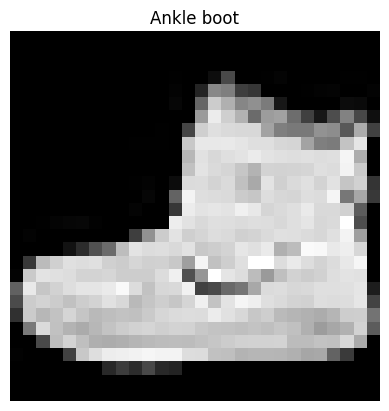

In [3]:
labels = [
    "T-shirt", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

image, label = train_data[0]

plt.imshow(image.squeeze(), cmap="gray")
plt.title(labels[label])
plt.axis("off")
plt.show()

In [4]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_data,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_data,
    batch_size=64,
    shuffle=False
)

In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class FashionCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(16 * 14 * 14, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = torch.flatten(x, start_dim=1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

model = FashionCNN()

print(model)

FashionCNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [6]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.parameters(), lr=0.001)

In [7]:
num_epochs = 5

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0

    for images, labels_batch in train_loader:
        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels_batch)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    average_loss = running_loss / len(train_loader)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}], "
        f"Loss: {average_loss:.4f}"
    )

Epoch [1/5], Loss: 0.4627
Epoch [2/5], Loss: 0.3118
Epoch [3/5], Loss: 0.2638
Epoch [4/5], Loss: 0.2331
Epoch [5/5], Loss: 0.2056


In [8]:
correct = 0
total = 0

model.eval()

with torch.no_grad():
    for images, labels_batch in test_loader:
        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels_batch.size(0)
        correct += (predicted == labels_batch).sum().item()

accuracy = 100 * correct / total

print(f"테스트 정확도: {accuracy:.2f}%")
print(f"정답 개수: {correct} / {total}")

테스트 정확도: 90.70%
정답 개수: 9070 / 10000


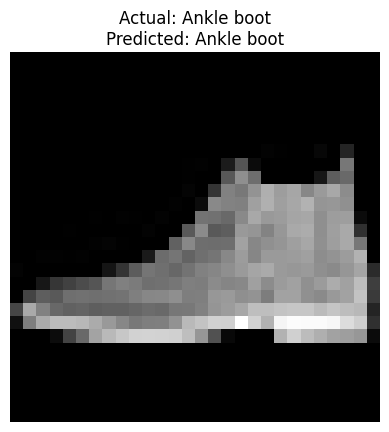

실제 정답: Ankle boot
AI 예측: Ankle boot


In [9]:
import matplotlib.pyplot as plt

image, true_label = test_data[0]

image_batch = image.unsqueeze(0)

model.eval()

with torch.no_grad():
    output = model(image_batch)
    predicted_label = output.argmax(dim=1).item()

plt.imshow(image.squeeze(), cmap="gray")
plt.title(
    f"Actual: {labels[true_label]}\n"
    f"Predicted: {labels[predicted_label]}"
)
plt.axis("off")
plt.show()

print("실제 정답:", labels[true_label])
print("AI 예측:", labels[predicted_label])

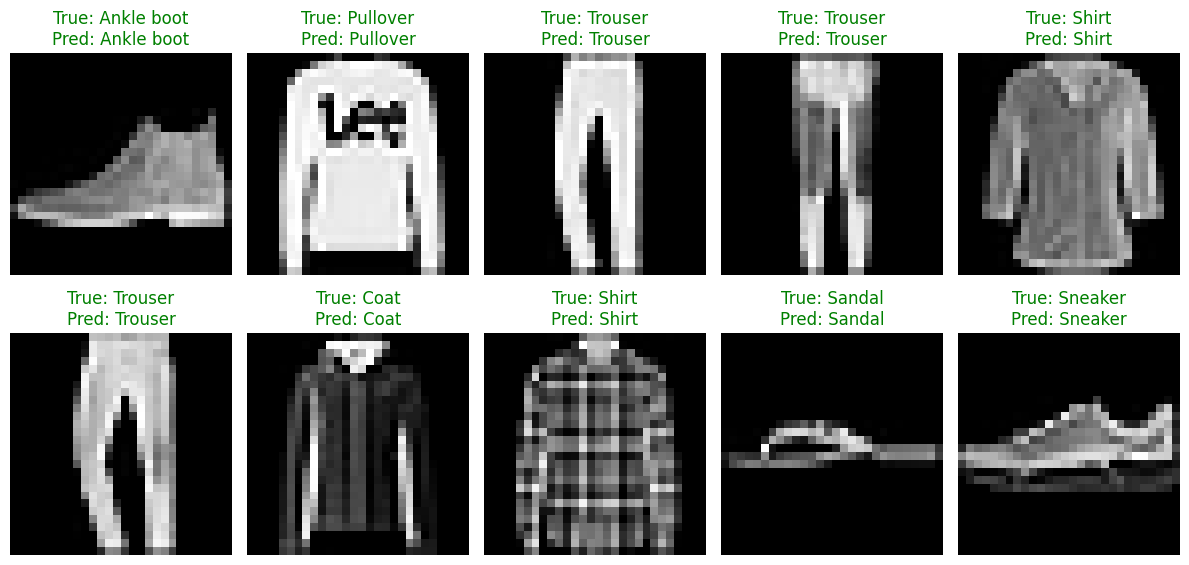

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(12, 6))

model.eval()

with torch.no_grad():
    for i, ax in enumerate(axes.flat):
        image, true_label = test_data[i]

        output = model(image.unsqueeze(0))
        predicted_label = output.argmax(dim=1).item()

        ax.imshow(image.squeeze(), cmap="gray")
        ax.set_title(
            f"True: {labels[true_label]}\n"
            f"Pred: {labels[predicted_label]}",
            color="green" if predicted_label == true_label else "red"
        )
        ax.axis("off")

plt.tight_layout()
plt.show()

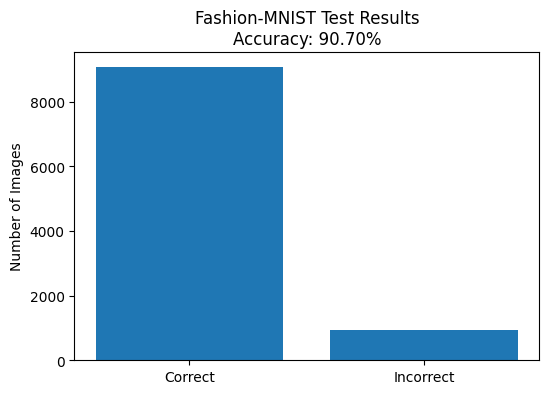

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))

plt.bar(
    ["Correct", "Incorrect"],
    [correct, total - correct]
)

plt.title(f"Fashion-MNIST Test Results\nAccuracy: {accuracy:.2f}%")
plt.ylabel("Number of Images")
plt.show()

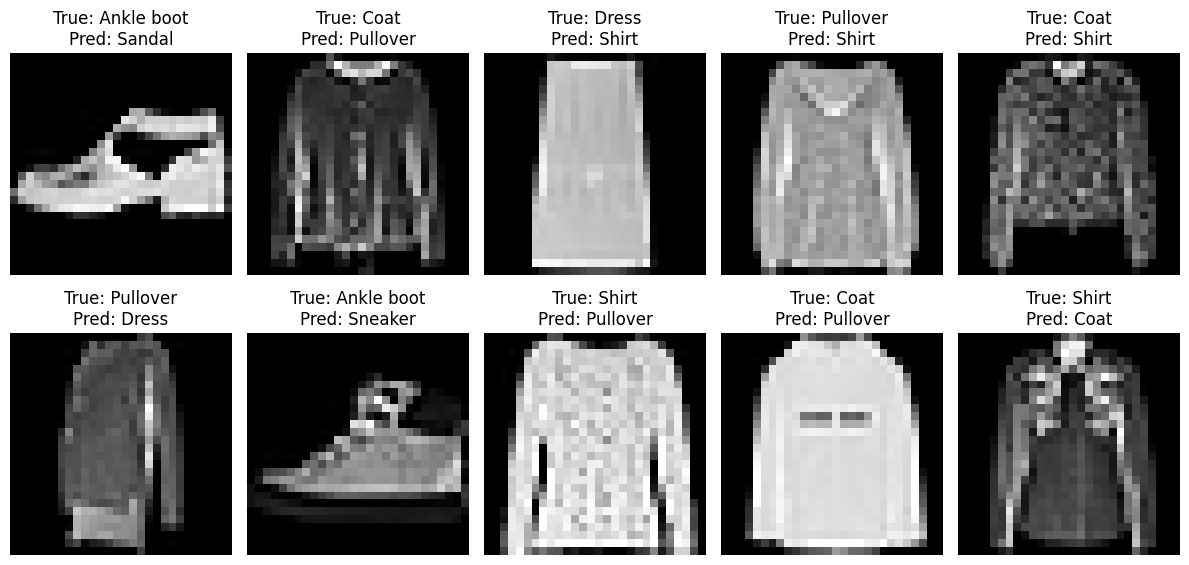

In [12]:
import matplotlib.pyplot as plt

wrong_images = []
wrong_labels = []
predicted_labels = []

model.eval()

with torch.no_grad():
    for images, labels_batch in test_loader:
        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        wrong_indices = (predictions != labels_batch).nonzero(
            as_tuple=True
        )[0]

        for idx in wrong_indices:
            wrong_images.append(images[idx].cpu())
            wrong_labels.append(labels_batch[idx].item())
            predicted_labels.append(predictions[idx].item())

            if len(wrong_images) >= 10:
                break

        if len(wrong_images) >= 10:
            break

fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(wrong_images[i].squeeze(), cmap="gray")
    ax.set_title(
        f"True: {labels[wrong_labels[i]]}\n"
        f"Pred: {labels[predicted_labels[i]]}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()